# Fat tails and volatility regimes in short-horizon BTC moves (Binance trades)

*The code was written by an AI assistant (Claude) from my instructions; see [How this was made](../README.md#how-this-was-made).*

**Data period:** 20 March to 5 April 2026 (UTC), Binance trades from the same live capture as notebooks 01 and 02, spread over 17 calendar days with gaps (about 14.2 days of data).

**Question.** For a forward move over H seconds, how does its distribution depend on the recent volatility regime,
and how far is it from a Normal distribution?

`move(H) = (price(t+H) - price(t)) / price(t) × 10 000` (basis points), sampled once per second. Regimes are
quintiles of the trailing 60-second realised volatility. Normal distribution: kurtosis = 3.

**Data:** 54,658,892 Binance BTCUSDT trades from my live capture (March to early April 2026, with gaps);
1,225,538 one-second bars that contain at least one trade, about 14.2 days of data.

## 1. Load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 130, 'font.size': 9,
    'axes.grid': True, 'grid.alpha': 0.2,
    'axes.spines.top': False, 'axes.spines.right': False,
})

DATA = Path('data')   # folder that contains binance_spot/

def find_feed(base, name):
    for sub in ['', 'server_data', 'data']:
        p = base / sub / name if sub else base / name
        if p.exists():
            print(f'  {name}: {p}')
            return p
    raise FileNotFoundError(name)

BN_DIR = find_feed(DATA, 'binance_spot')

  binance_spot: data/binance_spot


In [2]:
bn_dfs = []
for f in sorted(BN_DIR.glob('*.csv*')):
    try:
        bn_dfs.append(pd.read_csv(f, usecols=['local_ms','price'], on_bad_lines='skip'))
    except Exception:
        try:
            df = pd.read_csv(f, on_bad_lines='skip')
            bn_dfs.append(df[['local_ms','price']])
        except: pass

bn = pd.concat(bn_dfs, ignore_index=True)
bn['local_ms'] = pd.to_numeric(bn['local_ms'], errors='coerce')
bn['price']    = pd.to_numeric(bn['price'],    errors='coerce')
if bn['local_ms'].dropna().max() > 1e15:
    bn['local_ms'] = bn['local_ms'] // 1000
bn = bn.dropna().sort_values('local_ms', kind='stable').reset_index(drop=True)   # stable: same-millisecond trades keep their order
bn_times  = bn['local_ms'].values.astype(np.int64)
bn_prices = bn['price'].values.astype(np.float64)
print(f'BN ticks: {len(bn):,}')

BN ticks: 54,658,892


## 2. Build 1-Second Samples + Volatility Regime

In [3]:
# Resample BN to 1-second bars (last price per second)
bn_s = pd.DataFrame({'ts_s': bn_times // 1000, 'price': bn_prices})
bn_1s = bn_s.groupby('ts_s')['price'].last().reset_index()
bn_1s = bn_1s.sort_values('ts_s').reset_index(drop=True)
bn_1s['log_ret'] = np.log(bn_1s['price'] / bn_1s['price'].shift(1))
# shift(1): the label at second s uses returns up to s-1 only, so it never sees the move it is used to predict
bn_1s['rv_60s']  = bn_1s['log_ret'].rolling(60, min_periods=30).std().shift(1)

# 5 volatility regime edges from percentiles
rv_valid = bn_1s['rv_60s'].dropna()
edges = np.percentile(rv_valid, [0, 20, 40, 60, 80, 100])

REGIME_LABELS = ['Q1 Quiet', 'Q2 Slow', 'Q3 Normal', 'Q4 Active', 'Q5 Volatile']
REGIME_COLORS = ['#1565C0', '#2E7D32', '#F57F17', '#E65100', '#B71C1C']
HORIZONS_S    = [10, 100, 300]   # seconds
HORIZON_LABELS = ['10s', '100s', '300s']

bn_1s['regime'] = pd.cut(
    bn_1s['rv_60s'], bins=edges, labels=range(5), include_lowest=True
).astype('Int64')

print('1s bar count:', len(bn_1s))
print('Regime counts:')
print(bn_1s['regime'].value_counts().sort_index().to_string())
print()
print('RV edges (×10⁻⁴):')
for i, (lo, hi, lbl) in enumerate(zip(edges[:-1], edges[1:], REGIME_LABELS)):
    print(f'  {lbl}: [{lo*1e4:.2f}, {hi*1e4:.2f}]')

1s bar count: 1225538
Regime counts:
regime
0    245102
1    245102
2    245100
3    245101
4    245102

RV edges (×10⁻⁴):
  Q1 Quiet: [0.00, 0.24]
  Q2 Slow: [0.24, 0.38]
  Q3 Normal: [0.38, 0.53]
  Q4 Active: [0.53, 0.76]
  Q5 Volatile: [0.76, 15.15]


## 3. Compute forward moves

In [4]:
def compute_moves(times, prices, horizons_s, sample_times_s, sample_rv, name=''):
    """
    For each sample point (1 per second), compute forward moves at each horizon.
    Uses the price series (times, prices) with ms timestamps.
    
    Returns DataFrame with columns:
      ts_s, rv_60s, regime, move_10s, move_100s, move_300s
    """
    n = len(sample_times_s)
    results = {'ts_s': sample_times_s, 'rv_60s': sample_rv}

    for H in horizons_s:
        H_ms    = H * 1000
        col     = f'move_{H}s'
        moves   = np.full(n, np.nan)

        # Index of price at t (sample time)
        idx_now = np.searchsorted(times, sample_times_s * 1000, side='right') - 1
        # Index of price at t + H
        idx_fwd = np.searchsorted(times, sample_times_s * 1000 + H_ms, side='right') - 1

        valid = (
            (idx_now >= 0) & (idx_fwd >= 0) &
            (idx_now < len(prices)) & (idx_fwd < len(prices)) &
            (idx_fwd > idx_now)   # forward index must actually be after now
        )
        p_now = prices[np.clip(idx_now, 0, len(prices)-1)]
        p_fwd = prices[np.clip(idx_fwd, 0, len(prices)-1)]

        # Check time gap is within 20% of requested horizon (data gaps)
        t_now_ms = times[np.clip(idx_now, 0, len(times)-1)]
        t_fwd_ms = times[np.clip(idx_fwd, 0, len(times)-1)]
        gap_ok   = np.abs((t_fwd_ms - t_now_ms) - H_ms) < H_ms * 0.2

        ok = valid & gap_ok & (p_now > 0)
        moves[ok] = (p_fwd[ok] - p_now[ok]) / p_now[ok] * 10000
        results[col] = moves
        print(f'  H={H}s: {ok.sum():,} valid samples ({ok.mean()*100:.1f}%)')

    return pd.DataFrame(results)


# Sample points: every second where we have RV
sample_mask   = bn_1s['rv_60s'].notna() & bn_1s['regime'].notna()
sample_ts_s   = bn_1s.loc[sample_mask, 'ts_s'].values.astype(np.int64)
sample_rv     = bn_1s.loc[sample_mask, 'rv_60s'].values
sample_regime = bn_1s.loc[sample_mask, 'regime'].values

# BN moves (using raw BN ticks for precision)
bn_moves = compute_moves(bn_times, bn_prices, HORIZONS_S, sample_ts_s, sample_rv, name='BN')
bn_moves['regime'] = sample_regime

print(f'\nBN samples total: {len(bn_moves):,}')

  H=10s: 1,196,402 valid samples (97.6%)
  H=100s: 1,225,417 valid samples (100.0%)
  H=300s: 1,225,347 valid samples (100.0%)

BN samples total: 1,225,507


## 4. Distribution Plots — BN

**Layout:** 3 rows (horizons) × 5 columns (regimes)  
Each panel: histogram + KDE + fitted Normal + kurtosis

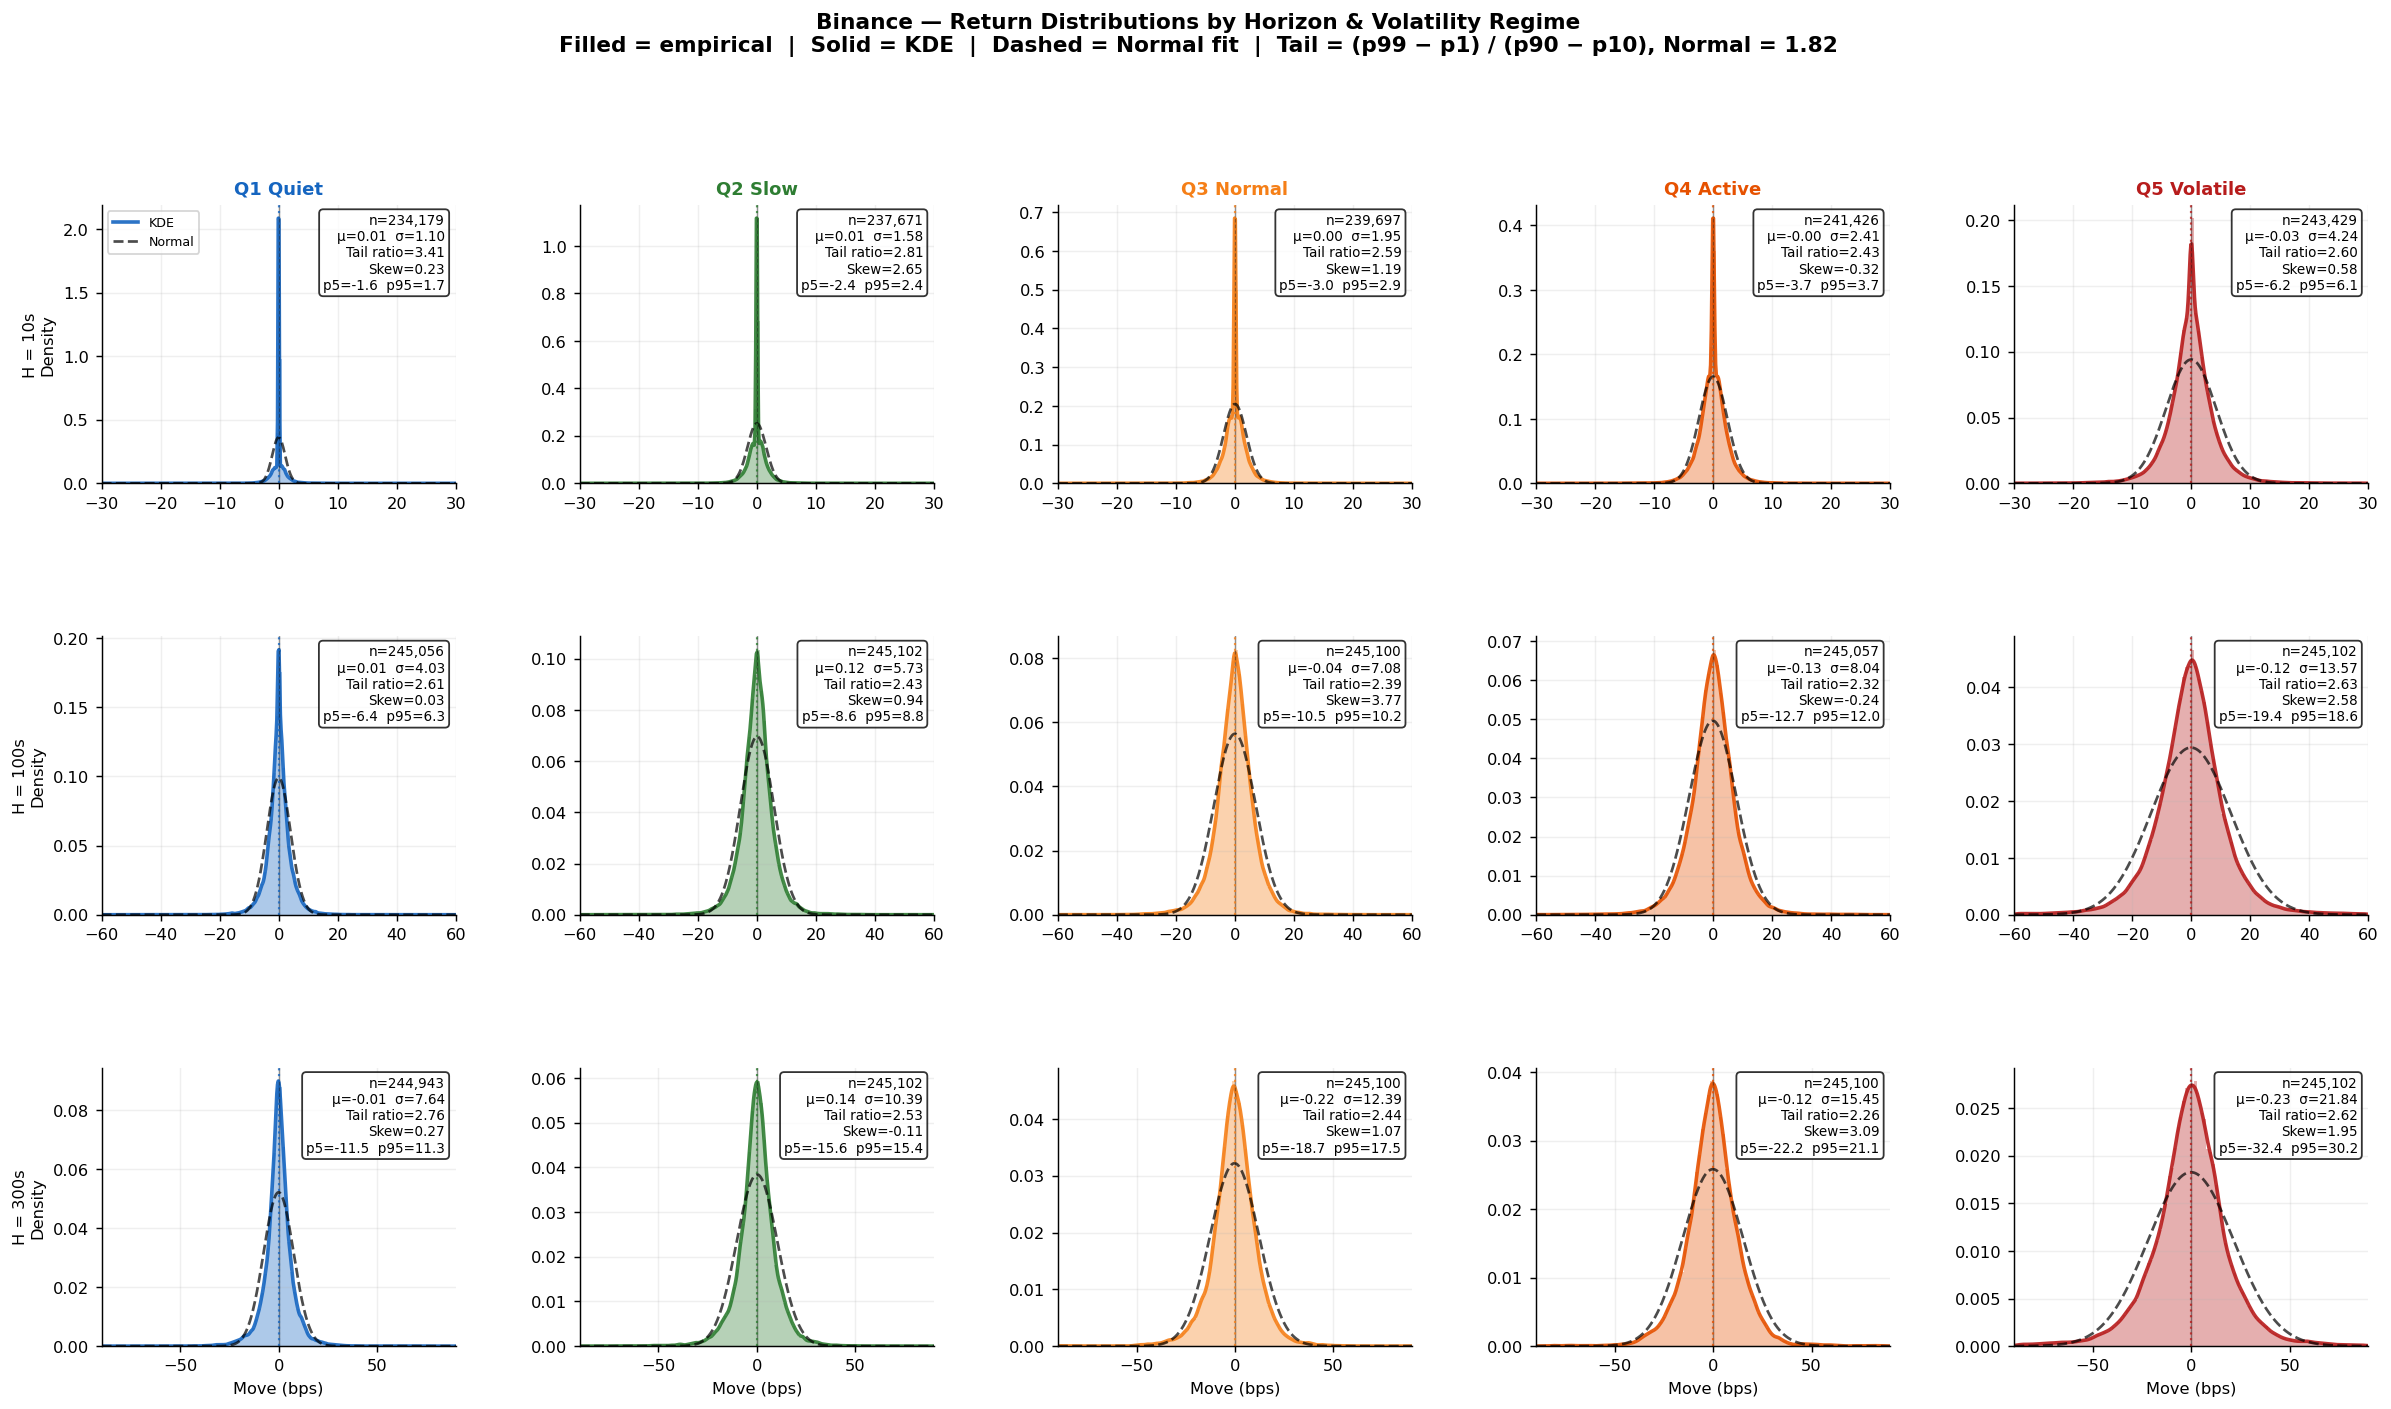

In [5]:
from scipy.stats import norm as sp_norm
from scipy.stats import kurtosis as sp_kurtosis

# Tail ratio: width of the 1st-99th percentile range over the width of the 10th-90th. It measures how fat the tails
# are, like kurtosis, but a handful of extreme moves cannot dominate it (section 6 shows they dominate the kurtosis).
# The 10th-90th is used rather than the middle half because in quiet regimes over 10 s more than half the moves are
# within a cent or two of zero, which would make the middle half almost zero wide. A Normal has 2.326 / 1.282 = 1.82.
TAIL_Q = (1, 10, 90, 99)
TAIL_NORMAL = (sp_norm.ppf(0.99) - sp_norm.ppf(0.01)) / (sp_norm.ppf(0.90) - sp_norm.ppf(0.10))

def tail_ratio(x):
    p1, p10, p90, p99 = np.percentile(x, TAIL_Q)
    return (p99 - p1) / (p90 - p10)

def in_range_density(data, clip, n_bins):
    # Histogram of the moves inside +-clip as a density of all moves: moves outside are left out, not piled at the edge
    counts, edges = np.histogram(data, bins=n_bins, range=(-clip, clip))
    return counts / (len(data) * (edges[1] - edges[0])), edges

def plot_distributions(moves_df, source_name, horizons_s, horizon_labels,
                       regime_labels, regime_colors, clip_bps=30):
    """
    Main distribution grid: rows=horizons, cols=regimes.
    Each panel: histogram (filled), KDE (solid), Normal fit (dashed), stats annotation.
    """
    n_h = len(horizons_s)
    n_r = len(regime_labels)
    fig, axes = plt.subplots(n_h, n_r, figsize=(4.5 * n_r, 3.8 * n_h),
                             gridspec_kw={'hspace': 0.55, 'wspace': 0.35})
    fig.suptitle(f'{source_name} — Return Distributions by Horizon & Volatility Regime\n'
                 f'Filled = empirical  |  Solid = KDE  |  Dashed = Normal fit  |  '
                 f'Tail = (p99 − p1) / (p90 − p10), Normal = {TAIL_NORMAL:.2f}',
                 fontsize=12, fontweight='bold', y=1.01)

    for row, (H, hlbl) in enumerate(zip(horizons_s, horizon_labels)):
        col_name = f'move_{H}s'
        for col, (rlbl, rcol) in enumerate(zip(regime_labels, regime_colors)):
            ax   = axes[row, col]
            mask = (moves_df['regime'] == col) & moves_df[col_name].notna()
            data = moves_df.loc[mask, col_name].values
            data = data[np.isfinite(data)]

            if len(data) < 50:
                ax.text(0.5, 0.5, 'Insufficient\ndata',
                        ha='center', va='center', transform=ax.transAxes)
                continue

            # Display range (keeps the axis readable); moves outside it are not drawn
            clip = clip_bps * (1 + row)  # wider range for longer horizons
            inside = data[np.abs(data) <= clip]

            # Stats
            mu      = data.mean()
            sigma   = data.std()
            tail    = tail_ratio(data)                  # Normal = TAIL_NORMAL
            skew    = stats.skew(data)
            p5, p95 = np.percentile(data, [5, 95])

            # Histogram
            n_bins = min(120, max(40, len(data) // 200))
            dens, edges = in_range_density(data, clip, n_bins)
            ax.stairs(dens, edges, fill=True, color=rcol, alpha=0.35)

            # KDE
            try:
                kde  = stats.gaussian_kde(inside, bw_method='scott')
                xs   = np.linspace(-clip, clip, 500)
                ax.plot(xs, kde(xs) * len(inside) / len(data), color=rcol, lw=2.0, alpha=0.9, label='KDE')
            except Exception:
                pass

            # Normal fit with same mean and std
            xs_norm = np.linspace(-clip, clip, 500)
            ax.plot(xs_norm, sp_norm.pdf(xs_norm, mu, sigma),
                    color='black', lw=1.5, ls='--', alpha=0.7, label='Normal')

            # Reference lines
            ax.axvline(0,  color='black', lw=0.8, ls='-',  alpha=0.4)
            ax.axvline(mu, color=rcol,   lw=1.2, ls=':',  alpha=0.8)

            # Stats annotation
            txt = (f'n={len(data):,}\n'
                   f'μ={mu:.2f}  σ={sigma:.2f}\n'
                   f'Tail ratio={tail:.2f}\n'
                   f'Skew={skew:.2f}\n'
                   f'p5={p5:.1f}  p95={p95:.1f}')
            ax.text(0.97, 0.97, txt, transform=ax.transAxes,
                    fontsize=7.5, va='top', ha='right',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))

            # Labels
            if row == 0:
                ax.set_title(rlbl, fontsize=10, fontweight='bold', color=rcol)
            if col == 0:
                ax.set_ylabel(f'H = {hlbl}\nDensity', fontsize=9)
            ax.set_xlabel('Move (bps)' if row == n_h-1 else '')
            ax.set_xlim(-clip, clip)

            if row == 0 and col == 0:
                ax.legend(fontsize=7, loc='upper left')

    fname = f'../figures/03_distributions_{source_name.lower().replace(" ","_")}.png'
    plt.savefig(fname, dpi=130, bbox_inches='tight')
    plt.show()


plot_distributions(bn_moves, 'Binance', HORIZONS_S, HORIZON_LABELS,
                   REGIME_LABELS, REGIME_COLORS)

## 5. Overlay — All Regimes on One Axis per Horizon

Directly shows how the distribution widens with volatility regime.

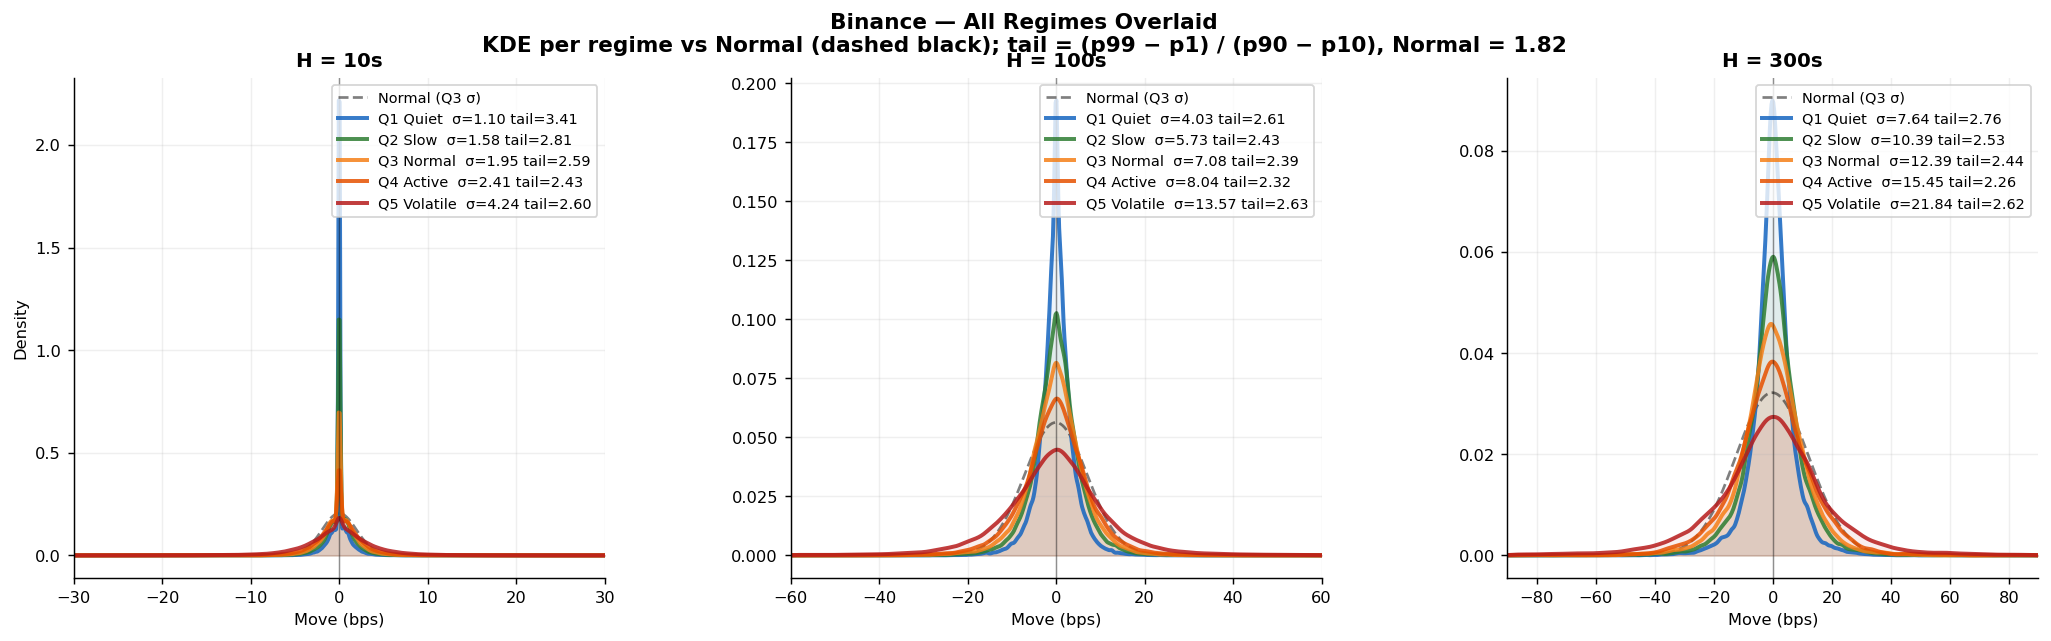

In [6]:
def plot_overlay(moves_df, source_name, horizons_s, horizon_labels,
                 regime_labels, regime_colors, clip_bps=30):
    """
    One column per horizon.
    All 5 regime KDEs overlaid on same axes + Normal reference.
    """
    n_h = len(horizons_s)
    fig, axes = plt.subplots(1, n_h, figsize=(6.5 * n_h, 5),
                             gridspec_kw={'wspace': 0.35})
    fig.suptitle(f'{source_name} — All Regimes Overlaid\nKDE per regime vs Normal (dashed black); '
                 f'tail = (p99 − p1) / (p90 − p10), Normal = {TAIL_NORMAL:.2f}',
                 fontsize=12, fontweight='bold')

    for col, (H, hlbl) in enumerate(zip(horizons_s, horizon_labels)):
        ax       = axes[col]
        col_name = f'move_{H}s'
        clip     = clip_bps * (1 + col)
        xs       = np.linspace(-clip, clip, 600)

        # Normal reference — use Q3 Normal regime as the reference std
        ref_mask = (moves_df['regime'] == 2) & moves_df[col_name].notna()
        ref_data = moves_df.loc[ref_mask, col_name].dropna()
        if len(ref_data) > 50:
            ax.plot(xs, sp_norm.pdf(xs, ref_data.mean(), ref_data.std()),
                    color='black', lw=1.5, ls='--', alpha=0.5,
                    label='Normal (Q3 σ)')

        for reg_idx, (rlbl, rcol) in enumerate(zip(regime_labels, regime_colors)):
            mask = (moves_df['regime'] == reg_idx) & moves_df[col_name].notna()
            data = moves_df.loc[mask, col_name].values
            data = data[np.isfinite(data)]
            if len(data) < 50: continue

            tail   = tail_ratio(data)
            sigma  = data.std()
            try:
                inside = data[np.abs(data) <= clip]
                kde = stats.gaussian_kde(inside, bw_method='scott')
                ys = kde(xs) * len(inside) / len(data)        # moves outside the range are not piled at its edges
                ax.plot(xs, ys, color=rcol, lw=2.2, alpha=0.85,
                        label=f'{rlbl}  σ={sigma:.2f} tail={tail:.2f}')
                ax.fill_between(xs, ys, alpha=0.07, color=rcol)
            except Exception:
                pass

        ax.axvline(0, color='black', lw=0.8, alpha=0.4)
        ax.set_title(f'H = {hlbl}', fontsize=11, fontweight='bold')
        ax.set_xlabel('Move (bps)')
        ax.set_ylabel('Density' if col == 0 else '')
        ax.set_xlim(-clip, clip)
        ax.legend(fontsize=8, loc='upper right')

    fname = f'../figures/03_overlay_{source_name.lower().replace(" ","_")}.png'
    plt.savefig(fname, dpi=130, bbox_inches='tight')
    plt.show()


plot_overlay(bn_moves, 'Binance',   HORIZONS_S, HORIZON_LABELS, REGIME_LABELS, REGIME_COLORS)

## 6. Kurtosis summary table and figures

In [7]:
def kurtosis_table(moves_df, source_name):
    rows = []
    for H in HORIZONS_S:
        col_name = f'move_{H}s'
        for reg_idx, rlbl in enumerate(REGIME_LABELS):
            mask = (moves_df['regime'] == reg_idx) & moves_df[col_name].notna()
            data = moves_df.loc[mask, col_name].dropna().values
            data = data[np.isfinite(data)]
            if len(data) < 50:
                continue
            rows.append({
                'Source':        source_name,
                'Horizon':       f'{H}s',
                'Regime':        rlbl,
                'n':             len(data),
                'mean':          round(data.mean(), 3),
                'std':           round(data.std(), 3),
                'skew':          round(float(stats.skew(data)), 3),
                'tail_ratio':    round(float(tail_ratio(data)), 2),
                'kurtosis':      round(float(sp_kurtosis(data, fisher=False)), 2),
                'p1':            round(np.percentile(data, 1), 2),
                'p5':            round(np.percentile(data, 5), 2),
                'p95':           round(np.percentile(data, 95), 2),
                'p99':           round(np.percentile(data, 99), 2),
            })
    return pd.DataFrame(rows)

bn_kt = kurtosis_table(bn_moves, 'BN')

print(f'=== TAIL TABLE: tail_ratio = (p99 - p1) / (p90 - p10), Normal = {TAIL_NORMAL:.2f}; kurtosis = all moves, Normal = 3 ===')
print(bn_kt[['Source','Horizon','Regime','n','std','tail_ratio','kurtosis','p5','p95']].to_string(index=False))

=== TAIL TABLE: tail_ratio = (p99 - p1) / (p90 - p10), Normal = 1.82; kurtosis = all moves, Normal = 3 ===
Source Horizon      Regime      n    std  tail_ratio  kurtosis     p5   p95
    BN     10s    Q1 Quiet 234179  1.103        3.41     40.68  -1.62  1.65
    BN     10s     Q2 Slow 237671  1.581        2.81    132.35  -2.41  2.35
    BN     10s   Q3 Normal 239697  1.946        2.59     38.41  -2.99  2.95
    BN     10s   Q4 Active 241426  2.410        2.43     18.49  -3.74  3.68
    BN     10s Q5 Volatile 243429  4.238        2.60     23.39  -6.19  6.12
    BN    100s    Q1 Quiet 245056  4.029        2.61     11.81  -6.36  6.28
    BN    100s     Q2 Slow 245102  5.727        2.43     21.28  -8.57  8.77
    BN    100s   Q3 Normal 245100  7.082        2.39    172.24 -10.54 10.20
    BN    100s   Q4 Active 245057  8.042        2.32      9.64 -12.69 12.04
    BN    100s Q5 Volatile 245102 13.571        2.63     56.98 -19.44 18.58
    BN    300s    Q1 Quiet 244943  7.640        2.76     

### What drives the large kurtosis values?

Kurtosis is the fourth moment, so a few extreme moves can dominate it. For each cell: the share of the fourth moment
that comes from the largest 0.1% of samples, the kurtosis without them, and a 95% interval from resampling whole days
(`N_BOOT` times; samples inside a day overlap and are not independent). Then the largest separate moves in the cell with
the highest kurtosis, with their times, so they can be checked against the market at that moment.

In [8]:
N_BOOT, SEED = 1000, 7
TOP = 0.001                                         # the largest 0.1% of samples by size

def kurt_from_sums(n, s1, s2, s3, s4):
    # Raw kurtosis (Normal = 3) from sums of x, x², x³, x⁴
    m1, m2, m3, m4 = s1 / n, s2 / n, s3 / n, s4 / n
    var = m2 - m1 ** 2
    c4 = m4 - 4 * m1 * m3 + 6 * m1 ** 2 * m2 - 3 * m1 ** 4
    return c4 / var ** 2

day_all = (bn_moves['ts_s'].values // 86400).astype(np.int64)
days, day_idx_all = np.unique(day_all, return_inverse=True)
rng = np.random.default_rng(SEED)
BOOT_D = np.stack([np.bincount(rng.integers(0, len(days), len(days)), minlength=len(days))
                   for _ in range(N_BOOT)]).astype(np.float64)

rows = []
for H in HORIZONS_S:
    col = f'move_{H}s'
    for reg_idx, rlbl in enumerate(REGIME_LABELS):
        m = (bn_moves['regime'] == reg_idx).values & np.isfinite(bn_moves[col].values)
        x, di = bn_moves[col].values[m], day_idx_all[m]
        dev4 = (x - x.mean()) ** 4
        big = np.abs(x - x.mean()) >= np.quantile(np.abs(x - x.mean()), 1 - TOP)
        sums = np.stack([np.bincount(di, weights=x ** p, minlength=len(days)) for p in range(5)], axis=1)
        b = BOOT_D @ sums
        k_draws = kurt_from_sums(*b.T)
        lo, hi = np.percentile(k_draws, [2.5, 97.5])
        rows.append({'Horizon': f'{H}s', 'Regime': rlbl, 'n': len(x),
                     'kurtosis': sp_kurtosis(x, fisher=False), 'lo': lo, 'hi': hi,
                     'top_share_of_4th_moment': dev4[big].sum() / dev4.sum(),
                     'kurtosis_without_top': sp_kurtosis(x[~big], fisher=False),
                     'days': len(np.unique(di))})
kt_diag = pd.DataFrame(rows)
kt_diag.to_csv('kurtosis_diagnostics_binance.csv', index=False)
print(f'95% interval from resampling days ({len(days)} days); top = the largest {TOP:.1%} of samples')
print(kt_diag.round(3).to_string(index=False))

# The largest separate moves in the cell with the highest kurtosis
worst = kt_diag.loc[kt_diag['kurtosis'].idxmax()]
H = int(worst['Horizon'][:-1]); col = f'move_{H}s'
reg_idx = REGIME_LABELS.index(worst['Regime'])
cell = bn_moves[(bn_moves['regime'] == reg_idx) & bn_moves[col].notna()]
cell = cell.reindex(cell[col].abs().sort_values(ascending=False).index)
picked = []
for ts, mv in zip(cell['ts_s'].values, cell[col].values):
    if all(abs(ts - p) > H for p, _ in picked):    # a separate move: starts more than H seconds from one already listed
        picked.append((ts, mv))
    if len(picked) == 5:
        break
print(f"\nLargest separate {worst['Horizon']} moves in {worst['Regime']} (cell std {cell[col].std():.2f} bps):")
for ts, mv in picked:
    print(f"  {pd.Timestamp(ts, unit='s')} UTC   {mv:+8.2f} bps   ({abs(mv) / cell[col].std():.0f} std)")

95% interval from resampling days (17 days); top = the largest 0.1% of samples
Horizon      Regime      n  kurtosis     lo      hi  top_share_of_4th_moment  kurtosis_without_top  days
    10s    Q1 Quiet 234179    40.679 17.842  71.336                    0.752                12.921    17
    10s     Q2 Slow 237671   132.355 13.103 288.973                    0.951                 8.680    17
    10s   Q3 Normal 239697    38.407 12.007  71.244                    0.851                 7.071    17
    10s   Q4 Active 241426    18.491 12.077  28.230                    0.709                 6.457    17
    10s Q5 Volatile 243429    23.387 15.281  28.870                    0.707                 8.628    17
   100s    Q1 Quiet 245056    11.809  7.536  16.636                    0.517                 6.465    17
   100s     Q2 Slow 245102    21.282  7.584  41.752                    0.768                 6.015    17
   100s   Q3 Normal 245100   172.240  9.298 385.794                    0.977     

The two figures below were **re-rendered from the table above** (the raw one-second samples are not stored in this
repo), using the original plotting code restricted to the Binance panel.

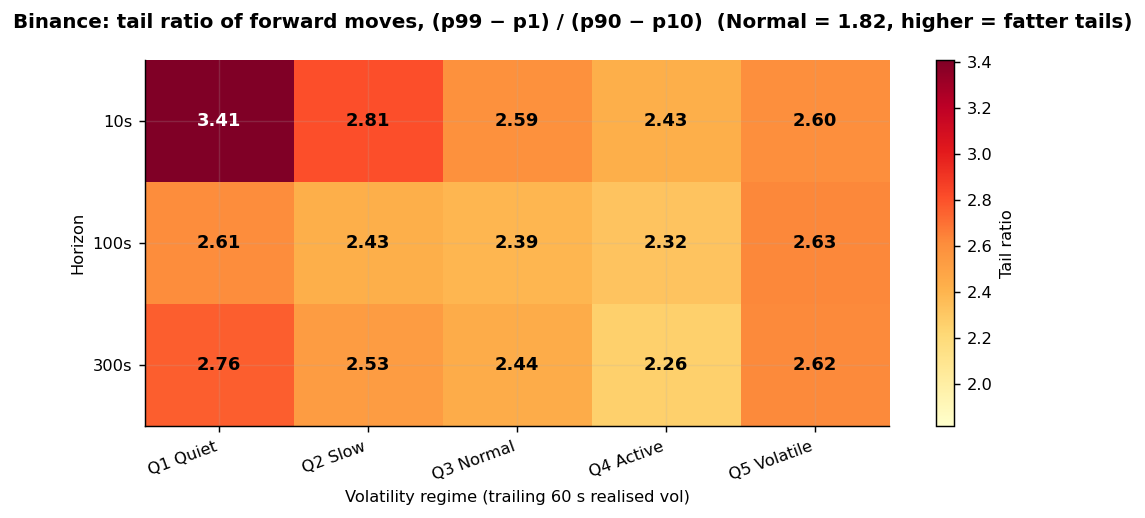

In [9]:
# Kurtosis heatmap: rows = horizons, columns = volatility regimes (Binance only)
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
fig.suptitle(f'Binance: tail ratio of forward moves, (p99 − p1) / (p90 − p10)  (Normal = {TAIL_NORMAL:.2f}, higher = fatter tails)',
             fontsize=11, fontweight='bold')

grid = np.full((len(HORIZONS_S), len(REGIME_LABELS)), np.nan)
for i, H in enumerate(HORIZONS_S):
    for j, rlbl in enumerate(REGIME_LABELS):
        row = bn_kt[(bn_kt['Horizon'] == f'{H}s') & (bn_kt['Regime'] == rlbl)]
        if len(row): grid[i, j] = row.iloc[0]['tail_ratio']

im = ax.imshow(grid, cmap='YlOrRd', aspect='auto', vmin=TAIL_NORMAL, vmax=np.nanmax(grid))
plt.colorbar(im, ax=ax, label='Tail ratio')
ax.set_xticks(range(len(REGIME_LABELS)))
ax.set_xticklabels(REGIME_LABELS, rotation=20, ha='right', fontsize=9)
ax.set_yticks(range(len(HORIZONS_S)))
ax.set_yticklabels(HORIZON_LABELS)
ax.set_xlabel('Volatility regime (trailing 60 s realised vol)')
ax.set_ylabel('Horizon')

for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        if not np.isnan(grid[i, j]):
            ax.text(j, i, f'{grid[i,j]:.2f}',
                    ha='center', va='center', fontsize=10, fontweight='bold',
                    color='white' if grid[i,j] > TAIL_NORMAL + 0.65 * (np.nanmax(grid) - TAIL_NORMAL) else 'black')

plt.tight_layout()
Path('../figures').mkdir(exist_ok=True)
plt.savefig('../figures/03_tail_ratio_heatmap_binance.png', dpi=130, bbox_inches='tight')
plt.show()

## 7. Std scaling: does the volatility of a move grow like √H?

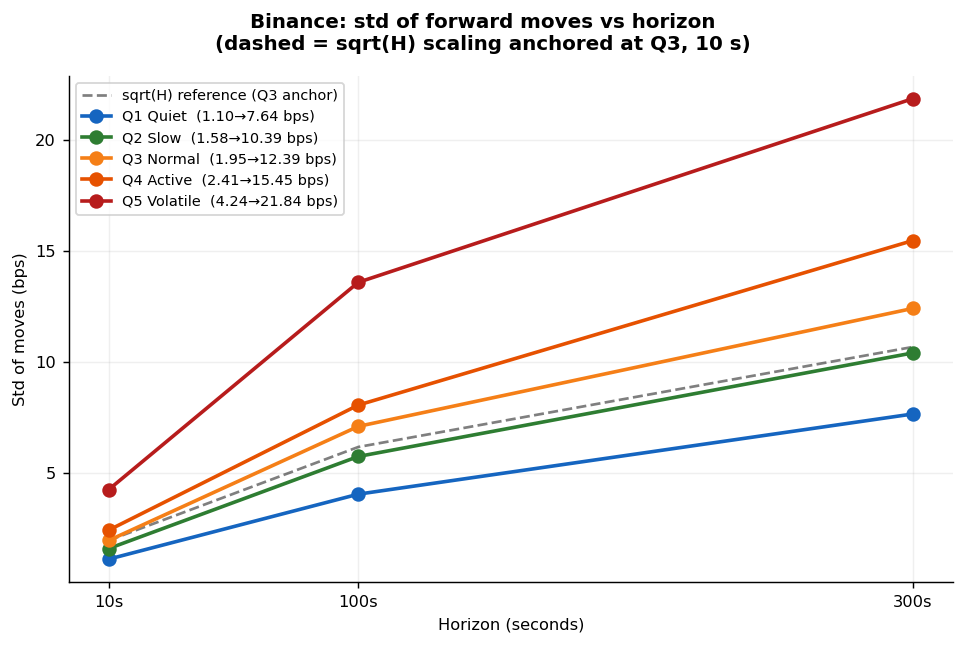

In [10]:
# If returns were i.i.d. Normal, the std of a move would grow like sqrt(H).
# Above the dashed line = grows faster than sqrt(H); below = slower.
fig, ax = plt.subplots(1, 1, figsize=(7.5, 5))
fig.suptitle('Binance: std of forward moves vs horizon\n'
             '(dashed = sqrt(H) scaling anchored at Q3, 10 s)',
             fontsize=11, fontweight='bold')

H_arr = np.array(HORIZONS_S, dtype=float)

# Reference: sqrt scaling anchored at 10s
ref_row = bn_kt[(bn_kt['Horizon'] == '10s') & (bn_kt['Regime'] == 'Q3 Normal')]
ref_std = ref_row.iloc[0]['std'] if len(ref_row) else 1.0
sqrt_ref = ref_std * np.sqrt(H_arr / 10)
ax.plot(H_arr, sqrt_ref, 'k--', lw=1.5, alpha=0.5, label='sqrt(H) reference (Q3 anchor)')

for reg_idx, (rlbl, rcol) in enumerate(zip(REGIME_LABELS, REGIME_COLORS)):
    stds = []
    for H in HORIZONS_S:
        row = bn_kt[(bn_kt['Horizon'] == f'{H}s') & (bn_kt['Regime'] == rlbl)]
        stds.append(row.iloc[0]['std'] if len(row) else np.nan)
    ax.plot(H_arr, stds, 'o-', color=rcol, lw=2, ms=7,
            label=f'{rlbl}  ({stds[0]:.2f}→{stds[-1]:.2f} bps)')

ax.set_xlabel('Horizon (seconds)')
ax.set_ylabel('Std of moves (bps)')
ax.set_xticks(H_arr)
ax.set_xticklabels(HORIZON_LABELS)
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('../figures/03_std_scaling_binance.png', dpi=130, bbox_inches='tight')
plt.show()

## Reading the results

* **Fat tails in every regime.** On all moves, every one of the 15 regime × horizon cells has kurtosis well above 3
  (9.6 to 172), and it stays well above 3 with the largest 0.1% of samples removed (5.6 to 12.9). A Gaussian model
  would understate tail risk in every regime.
* **The full-sample numbers are not stable.** The largest 0.1% of samples supply 46% to 98% of the fourth moment, and
  resampling whole days gives intervals such as 9 to 386 for the 172 of Q3 / 100 s. Samples are one per second, so the 100 s and 300 s moves
  also overlap heavily.
* **So the table and heatmap report a tail ratio instead:** the width of the 1st-to-99th percentile range over the
  width of the 10th-to-90th, `(p99 − p1) / (p90 − p10)`. It measures fat tails like kurtosis does, but a few extreme
  moves cannot dominate it. A Normal has 1.82; every cell here is between 2.26 and 3.41, 1.2 to 1.9 times that. The
  tails are fattest in the quietest regime at 10 s (3.41), where a rare jump stands out most, and a little thinner at
  longer horizons, as moves add up.
* The std of the move grows faster than √H in calm regimes and more slowly in the most volatile one
  (10 s → 300 s: ×6.9 in Q1, ×5.2 in Q5, against √30 = 5.5 for a random walk with constant volatility). This is
  consistent with volatility regimes being temporary (calm periods end, wild ones calm down). I did not test that
  explanation separately.
* Regime edges (realised vol, ×10⁻⁴): Q1 0–0.24, Q2 0.24–0.38, Q3 0.38–0.53, Q4 0.53–0.76, Q5 0.76–15.15.

### Note on the regime label

The 60-second volatility used at second `s` is lagged by one second, so the regime label only uses prices from before
the forward move starts. Without the lag, the first second of every forward window would also feed its own label (10%
of the window at H = 10 s, 1% at 100 s, 0.3% at 300 s), sorting a second's own jump into a wilder regime.
